# CDS 4003: Mobile Game In-App Purchases
## Stage 5: Model Selection and Development
**Models Implemented:** Decision Tree and XGBoost

## Model 1: Decision Tree Classifier

In this section, we train a Decision Tree classifier to predict the `SpendingSegment` (Minnow, Dolphin, Whale).

**Preprocessing Decisions:**
Following the project requirements, we excluded `UserID` and `InAppPurchaseAmount` from the features to prevent target leakage, as `InAppPurchaseAmount` directly reveals the spending segment. Missing values were dropped, and categorical variables were one-hot encoded.

**Handling Class Imbalance:**
Because the dataset is highly imbalanced (Minnows make up 85% of players, while Whales are only 2%), we applied `class_weight='balanced'` to the model. This forces the Decision Tree to penalize mistakes on the minority classes (Dolphins and Whales) more heavily than the majority class.

**Hyperparameter Tuning:**
To find the most robust tree, we used `GridSearchCV` with 3-fold cross-validation. We tuned the `criterion` (comparing Gini and Entropy), `max_depth`, and `min_samples_leaf`. We optimized specifically for **Macro-F1** to ensure the model performs well across all three segments, rather than just being good at predicting Minnows.

Baseline Decision Trees
Baseline Gini Accuracy: 0.8384
Baseline Entropy Accuracy: 0.8336

Hyperparameter Tuning
Optimized Parameters: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 10}

FINAL OPTIMIZED DECISION TREE
Macro-F1 Score: 0.6133
Balanced Accuracy: 0.7724

Confusion Matrix:
[[31337  9870   459]
 [ 1176  4644   914]
 [    1   136   963]]

Classification Report:
              precision    recall  f1-score   support

     Dolphin       0.32      0.69      0.43      6734
      Minnow       0.96      0.75      0.84     41666
       Whale       0.41      0.88      0.56      1100

    accuracy                           0.75     49500
   macro avg       0.56      0.77      0.61     49500
weighted avg       0.86      0.75      0.78     49500



/tmp/ipykernel_608/3266984229.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="viridis")


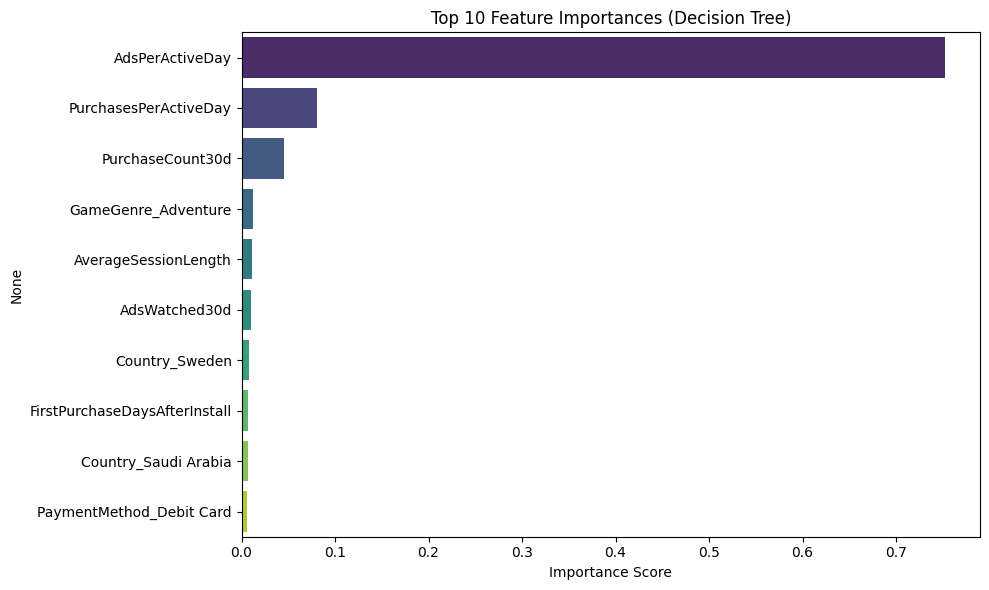

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, balanced_accuracy_score, f1_score

# Load the cleaned dataset
df = pd.read_csv("mobile_game_players_eda_features.csv")

# Pre-processing based on project instructions
# Drop UserID, and InAppPurchaseAmount (target leakage)
# Also drop date columns and missing flags for simplicity in modeling
drop_cols = ['UserID', 'InAppPurchaseAmount', 'InstallDate', 'LastPurchaseDate',
             'InAppPurchaseAmountWasMissing', 'FirstPurchaseDaysAfterInstallWasMissing',
             'AmountKnown', 'IAPForSummary']
df = df.drop(columns=[c for c in drop_cols if c in df.columns])

# Drop any remaining rows with missing values (for safety)
df = df.dropna()

# Separate Target and Features
X = df.drop(columns=['SpendingSegment'])
y = df['SpendingSegment']

# One-hot encode categorical variables (Device, Country, etc.)
X = pd.get_dummies(X, drop_first=True)

# Train-Test Split (80/20, stratified to keep the 85/13/2 ratio)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Decision Tree with Gini and Entropy
print("Baseline Decision Trees")

# Gini
dt_gini = DecisionTreeClassifier(criterion='gini', class_weight='balanced', random_state=42)
dt_gini.fit(X_train, y_train)
y_pred_gini = dt_gini.predict(X_test)
print(f"Baseline Gini Accuracy: {accuracy_score(y_test, y_pred_gini):.4f}")

# Entropy
dt_entropy = DecisionTreeClassifier(criterion='entropy', class_weight='balanced', random_state=42)
dt_entropy.fit(X_train, y_train)
y_pred_entropy = dt_entropy.predict(X_test)
print(f"Baseline Entropy Accuracy: {accuracy_score(y_test, y_pred_entropy):.4f}")

# Hyperparameter Tuning (Optimizing for Macro-F1 as required by project)
print("\nHyperparameter Tuning")
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [5, 10, 15],
    'min_samples_leaf': [10, 50, 100]
}

dt_opt = DecisionTreeClassifier(class_weight='balanced', random_state=42)
grid_search = GridSearchCV(dt_opt, param_grid, cv=3, scoring='f1_macro', n_jobs=-1)
grid_search.fit(X_train, y_train)

best_dt = grid_search.best_estimator_
print("Optimized Parameters:", grid_search.best_params_)

# Final Evaluation
y_pred_best = best_dt.predict(X_test)
print("\nFINAL OPTIMIZED DECISION TREE")
print(f"Macro-F1 Score: {f1_score(y_test, y_pred_best, average='macro'):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred_best):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best, labels=['Minnow', 'Dolphin', 'Whale']))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

# Feature Importance
importances = best_dt.feature_importances_
features = X.columns
feat_imp = pd.Series(importances, index=features).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="viridis")
plt.title("Top 10 Feature Importances (Decision Tree)")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.savefig("dt_feature_importance.png")
plt.show()

## Decision Tree Results & Insights

The optimized Decision Tree (Gini, max_depth=10) achieved a **Macro-F1 Score of 0.6133** and a **Balanced Accuracy of 0.7724**. Because of the severe class imbalance, overall accuracy (75%) is misleading. The model’s true success is in its class-specific performance: it successfully identified **88% of Whales** (Recall = 0.88) and **69% of Dolphins** (Recall = 0.69). This means the model is highly effective at flagging high-value players for loyalty campaigns.

The feature importance analysis reveals that **AdsPerActiveDay** and **PurchasesPerActiveDay** are the dominant predictors of a player's spending segment.

## Model 2: XGBoost Classifier

To improve upon the baseline Decision Tree, we implemented an XGBoost (Extreme Gradient Boosting) classifier. XGBoost is a highly optimized ensemble method that builds trees sequentially to correct the errors of previous trees, making it highly effective for complex, tabular data.

**Handling Class Imbalance:**
Because the target classes (Minnow, Dolphin, Whale) are highly imbalanced, we used the `compute_sample_weight` function from scikit-learn to apply balanced class weights. This ensures the XGBoost model pays equal attention to the minority classes.

**Model Setup & Tuning:**
We configured the model for multi-class classification (`objective='multi:softprob'`) and mapped the target labels to numeric values (Dolphin=0, Minnow=1, Whale=2). We used `GridSearchCV` with 3-fold cross-validation to tune the `max_depth` and `n_estimators`. Just like the Decision Tree, we optimized the search specifically for the **Macro-F1 score** to ensure the model performs well across all three spending segments.

XGBoost Model
Optimized Parameters: {'max_depth': 7, 'n_estimators': 100}
FINAL OPTIMIZED XGBOOST
Macro-F1 Score: 0.9155
Balanced Accuracy: 0.9592
Confusion Matrix:
[[ 6353   341    40]
 [ 1915 39645   106]
 [    6    13  1081]]
Classification Report:
              precision    recall  f1-score   support

     Dolphin       0.77      0.94      0.85      6734
      Minnow       0.99      0.95      0.97     41666
       Whale       0.88      0.98      0.93      1100

    accuracy                           0.95     49500
   macro avg       0.88      0.96      0.92     49500
weighted avg       0.96      0.95      0.95     49500



/tmp/ipykernel_608/444173813.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="magma")


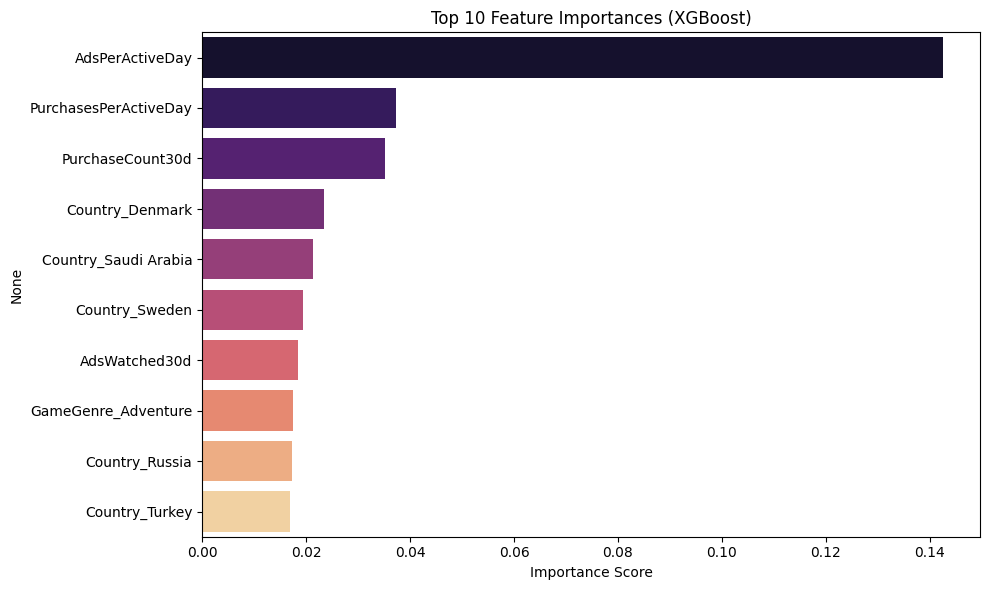

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score, f1_score, accuracy_score
from sklearn.utils.class_weight import compute_sample_weight

# Load the dataset
df = pd.read_csv("mobile_game_players_eda_features.csv")

# Pre-processing
# Drop UserID, InAppPurchaseAmount (target leakage), and Date columns
drop_cols = ['UserID', 'InAppPurchaseAmount', 'InstallDate', 'LastPurchaseDate',
             'InAppPurchaseAmountWasMissing', 'FirstPurchaseDaysAfterInstallWasMissing',
             'AmountKnown', 'IAPForSummary']

# Drop columns and drop any remaining missing values
df = df.drop(columns=[c for c in drop_cols if c in df.columns]).dropna()

X = df.drop(columns=['SpendingSegment'])
y = df['SpendingSegment']

# Map target to numbers for XGBoost (Dolphin=0, Minnow=1, Whale=2)
y = y.map({'Dolphin': 0, 'Minnow': 1, 'Whale': 2})

# One-hot encode categorical variables
X = pd.get_dummies(X, drop_first=True)

# Train-Test Split (80/20, stratified to keep the 85/13/2 ratio)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Calculate sample weights to handle the 85/13/2 class imbalance
weights = compute_sample_weight(class_weight='balanced', y=y_train)

print("XGBoost Model")

# Setup the XGBoost model for multi-class classification
xgb_model = XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    random_state=42,
    eval_metric='mlogloss'
)

# Hyperparameter Tuning
param_grid_xgb = {
    'max_depth': [3, 5, 7],
    'n_estimators': [50, 100]
}

# Optimize for Macro-F1 as required by your project
grid_xgb = GridSearchCV(xgb_model, param_grid_xgb, cv=3, scoring='f1_macro', n_jobs=-1)

# Fit the model using the sample weights
grid_xgb.fit(X_train, y_train, sample_weight=weights)

best_xgb = grid_xgb.best_estimator_
print("Optimized Parameters:", grid_xgb.best_params_)

# Evaluation
y_pred_xgb = best_xgb.predict(X_test)

print("FINAL OPTIMIZED XGBOOST")
print(f"Macro-F1 Score: {f1_score(y_test, y_pred_xgb, average='macro'):.4f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred_xgb):.4f}")

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb, labels=[0, 1, 2]))

print("Classification Report:")
print(classification_report(y_test, y_pred_xgb, target_names=['Dolphin', 'Minnow', 'Whale']))

# Feature Importance Graph
importances = best_xgb.feature_importances_
features = X.columns
feat_imp = pd.Series(importances, index=features).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette="magma")
plt.title("Top 10 Feature Importances (XGBoost)")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.savefig("xgb_feature_importance.png")
plt.show()

## XGBoost Results & Insights

The optimized XGBoost model achieved a **Macro-F1 Score of 0.9155** and a **Balanced Accuracy of 0.9592**.

Compared to the Decision Tree, XGBoost performed exceptionally well in identifying the minority classes. Specifically, it achieved a **Whale Recall of 0.98** (successfully identifying 1,081 out of 1,100 Whales) and a **Dolphin Recall of 0.94**. This proves that XGBoost is highly effective at overcoming the severe 85/13/2 class imbalance.

The feature importance analysis for XGBoost confirms the findings from the Decision Tree, showing that **AdsPerActiveDay** and **PurchasesPerActiveDay** remain the most critical features for predicting a player's spending tier.

## Baseline Comparison (Dummy Classifier)
To verify that our models are genuinely learning patterns and not simply guessing the majority class, we compared them against a DummyClassifier baseline.

In [7]:
# Baseline Dummy Classifier to prove why Accuracy is misleading
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

print("Baseline Dummy Classifier Results")
# The dummy classifier simply predicts the most frequent class (Minnow) for everything
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

# Printing the metrics
print(f"Dummy Accuracy: {accuracy_score(y_test, y_pred_dummy):.4f}")
print(f"Dummy Macro-F1: {f1_score(y_test, y_pred_dummy, average='macro'):.4f}")
print(f"Dummy Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred_dummy):.4f}")

Baseline Dummy Classifier Results
Dummy Accuracy: 0.8417
Dummy Macro-F1: 0.3047
Dummy Balanced Accuracy: 0.3333
